In [1]:
import gifba
from scipy.integrate import solve_ivp
import numpy as np
import cobra as cb
import pandas as pd
from IPython.display import clear_output
import copy
import matplotlib.pyplot as plt
from cobra import Model
import os
from pathlib import Path
import json
import tol_colors as tol
import plotly.express as px

In [2]:
# import all files from benchmark_results
RESULTS_DIR = Path(os.getcwd()) / "Benchmark_AH_BI"

# Load all JSON files in the results directory
results = {
    file.stem: json.loads(file.read_text())
    for file in RESULTS_DIR.glob("*.json")
}
df = pd.DataFrame.from_dict(results, orient="index")
print(df.columns)
# keep all where status = "dfba_complete" or starts with "dfba_in_progress_..."
dfba_complete_mask = df["status"] == "dfba_complete"
dfba_in_prog_mask = df["status"].str.startswith("dfba_in_progress_")
df = df[dfba_complete_mask | dfba_in_prog_mask]

print("Number of rows dropped:", len(df)- (dfba_complete_mask | dfba_in_prog_mask).sum())

# set dfba_solve time=max_time - gifba-solve_time where status starts with "dfba_in_progress..."
max_time = 24 * 3600 # 1 day minutes in seconds
df.loc[dfba_in_prog_mask, "dfba_solve_time"] = max_time

# drop gifba time/pfba calls & dfba, replace with log10(gifba/dfba) ratio
log10_time_ratio = np.log10(df["dfba_solve_time"] / df["gifba_solve_time"])
df["log10_time_ratio"] = log10_time_ratio

log10_pfba_call_ratio = np.log10(df["dfba_pfba_calls"] / df["gifba_pfba_calls"])
df["log10_pfba_call_ratio"] = log10_pfba_call_ratio

# if rel_abund column exists, replace list with first value of list
if "rel_abund" in df.columns:
    df["rel_abund"] = df["rel_abund"].apply(lambda x: x[0] if isinstance(x, list) and len(x) > 0 else np.nan)

df

Index(['N_models', 'model_names', 'rel_abund', 'y0_factor', 'y0_offset',
       'media', 'sum_N_rxns', 'sum_N_mets', 'vmax', 'km', 'solver_method',
       'early_stop_window', 'early_stop_tol', 'model_solver',
       'gifba_solve_time', 'dfba_solve_time', 'gifba_pfba_calls',
       'dfba_pfba_calls', 'dfba_status', 'error', 'status', 'gifba_fluxes',
       'dfba_fluxes', 'gifba_iter_converged', 'gifba_periodicity',
       'dfba_success', 'dfba_message', 'dfba_termination_t'],
      dtype='object')
Number of rows dropped: 0


,N_models,model_names,rel_abund,y0_factor,y0_offset,media,sum_N_rxns,sum_N_mets,vmax,km,...,status,gifba_fluxes,dfba_fluxes,gifba_iter_converged,gifba_periodicity,dfba_success,dfba_message,dfba_termination_t,log10_time_ratio,log10_pfba_call_ratio
5856212_462,2,[Bifidobacterium_longum_infantis_ATCC_15697.ma...,0.883838,0.107227,0.000159,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,23.644894,0.359381,...,dfba_complete,"{'ACOAAGPATAI17': {'0': 0.0, '1': 0.0}, 'BACCL...","{'ACOAAGPATAI17': {'0': 0.0, '1': 0.0}, 'BACCL...",4,1,True,The solver successfully reached the end of the...,100.0,0.518475,1.682145
5856212_39,2,[Bifidobacterium_longum_infantis_ATCC_15697.ma...,0.544444,0.497702,0.005214,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,18.738174,0.443062,...,dfba_complete,"{'NTD11': {'0': 0.0, '1': 0.0}, 'CBLtle': {'0'...","{'NTD11': {'0': 0.0, '1': 0.0}, 'CBLtle': {'0'...",5,1,True,The solver successfully reached the end of the...,100.0,1.142636,2.116995
5856212_180,2,[Bifidobacterium_longum_infantis_ATCC_15697.ma...,0.641414,0.065793,0.000285,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,6.135907,0.170735,...,dfba_complete,"{'ACOAAGPATI16': {'0': 0.0, '1': 0.0}, 'GLYPRO...","{'ACOAAGPATI16': {'0': 0.0, '1': 0.0}, 'GLYPRO...",5,1,True,The solver successfully reached the end of the...,100.0,0.092616,0.985277
5856212_43,2,[Bifidobacterium_longum_infantis_ATCC_15697.ma...,0.302020,0.030539,0.059948,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,45.348785,0.954548,...,dfba_complete,"{'ACONT': {'0': 0.0, '1': 0.0}, 'DASYN160': {'...","{'ACONT': {'0': 0.0, '1': 0.0}, 'DASYN160': {'...",6,1,True,The solver successfully reached the end of the...,100.0,1.773718,2.676302
5856212_490,2,[Bifidobacterium_longum_infantis_ATCC_15697.ma...,0.326263,0.187382,0.047508,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,10.235310,0.319927,...,dfba_complete,"{'PGMT': {'0': -0.059726567680603124, '1': -0....","{'PGMT': {'0': -0.03901095204563988, '1': -0.0...",5,1,True,The solver successfully reached the end of the...,100.0,-0.136829,0.937852
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5856212_305,2,[Bifidobacterium_longum_infantis_ATCC_15697.ma...,0.697980,0.065793,0.053367,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,2.310130,0.126186,...,dfba_complete,"{'FUM': {'0': 0.18279610707505198, '1': 0.0205...","{'FUM': {'0': 0.04222140865423573, '1': 0.0047...",5,1,True,The solver successfully reached the end of the...,100.0,0.668936,1.633468
5856212_483,2,[Bifidobacterium_longum_infantis_ATCC_15697.ma...,0.132323,0.123285,1.747528,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,15.556761,0.259502,...,dfba_complete,"{'HACD9': {'0': 0.0, '1': 0.0}, 'IGPS': {'0': ...","{'HACD9': {'0': 0.0, '1': 0.0}, 'IGPS': {'0': ...",7,2,True,The solver successfully reached the end of the...,100.0,1.235808,2.024280
5856212_477,2,[Bifidobacterium_longum_infantis_ATCC_15697.ma...,0.180808,0.075646,0.005857,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,22.570197,0.599484,...,dfba_complete,"{'DMPPS2r': {'0': 0.0, '1': 0.0101161270997841...","{'DMPPS2r': {'0': -0.6838017937351895, '1': 0....",8,2,True,The solver successfully reached the end of the...,100.0,0.866247,1.679731
5856212_71,2,[Bifidobacterium_longum_infantis_ATCC_15697.ma...,0.245455,0.006579,0.084975,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,8.902151,0.403702,...,dfba_complete,"{'RAFH': {'0': 0.0, '1': 0.0}, '3HAD9M10': {'0...","{'RAFH': {'0': 0.0, '1': 0.0}, '3HAD9M10': {'0...",7,2,True,The solver successfully reached the end of the...,100.0,-0.056409,0.730378


In [3]:
# save each model_names in case later is needed
model_names = df['model_names']

df.drop(columns=['model_names'], inplace=True)
df

,N_models,rel_abund,y0_factor,y0_offset,media,sum_N_rxns,sum_N_mets,vmax,km,solver_method,...,status,gifba_fluxes,dfba_fluxes,gifba_iter_converged,gifba_periodicity,dfba_success,dfba_message,dfba_termination_t,log10_time_ratio,log10_pfba_call_ratio
5856212_462,2,0.883838,0.107227,0.000159,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,23.644894,0.359381,BDF,...,dfba_complete,"{'ACOAAGPATAI17': {'0': 0.0, '1': 0.0}, 'BACCL...","{'ACOAAGPATAI17': {'0': 0.0, '1': 0.0}, 'BACCL...",4,1,True,The solver successfully reached the end of the...,100.0,0.518475,1.682145
5856212_39,2,0.544444,0.497702,0.005214,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,18.738174,0.443062,BDF,...,dfba_complete,"{'NTD11': {'0': 0.0, '1': 0.0}, 'CBLtle': {'0'...","{'NTD11': {'0': 0.0, '1': 0.0}, 'CBLtle': {'0'...",5,1,True,The solver successfully reached the end of the...,100.0,1.142636,2.116995
5856212_180,2,0.641414,0.065793,0.000285,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,6.135907,0.170735,RK45,...,dfba_complete,"{'ACOAAGPATI16': {'0': 0.0, '1': 0.0}, 'GLYPRO...","{'ACOAAGPATI16': {'0': 0.0, '1': 0.0}, 'GLYPRO...",5,1,True,The solver successfully reached the end of the...,100.0,0.092616,0.985277
5856212_43,2,0.302020,0.030539,0.059948,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,45.348785,0.954548,RK45,...,dfba_complete,"{'ACONT': {'0': 0.0, '1': 0.0}, 'DASYN160': {'...","{'ACONT': {'0': 0.0, '1': 0.0}, 'DASYN160': {'...",6,1,True,The solver successfully reached the end of the...,100.0,1.773718,2.676302
5856212_490,2,0.326263,0.187382,0.047508,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,10.235310,0.319927,RK45,...,dfba_complete,"{'PGMT': {'0': -0.059726567680603124, '1': -0....","{'PGMT': {'0': -0.03901095204563988, '1': -0.0...",5,1,True,The solver successfully reached the end of the...,100.0,-0.136829,0.937852
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5856212_305,2,0.697980,0.065793,0.053367,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,2.310130,0.126186,BDF,...,dfba_complete,"{'FUM': {'0': 0.18279610707505198, '1': 0.0205...","{'FUM': {'0': 0.04222140865423573, '1': 0.0047...",5,1,True,The solver successfully reached the end of the...,100.0,0.668936,1.633468
5856212_483,2,0.132323,0.123285,1.747528,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,15.556761,0.259502,BDF,...,dfba_complete,"{'HACD9': {'0': 0.0, '1': 0.0}, 'IGPS': {'0': ...","{'HACD9': {'0': 0.0, '1': 0.0}, 'IGPS': {'0': ...",7,2,True,The solver successfully reached the end of the...,100.0,1.235808,2.024280
5856212_477,2,0.180808,0.075646,0.005857,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,22.570197,0.599484,BDF,...,dfba_complete,"{'DMPPS2r': {'0': 0.0, '1': 0.0101161270997841...","{'DMPPS2r': {'0': -0.6838017937351895, '1': 0....",8,2,True,The solver successfully reached the end of the...,100.0,0.866247,1.679731
5856212_71,2,0.245455,0.006579,0.084975,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,8.902151,0.403702,RK45,...,dfba_complete,"{'RAFH': {'0': 0.0, '1': 0.0}, '3HAD9M10': {'0...","{'RAFH': {'0': 0.0, '1': 0.0}, '3HAD9M10': {'0...",7,2,True,The solver successfully reached the end of the...,100.0,-0.056409,0.730378


In [4]:
# discretize continuous variables


# min & max values (some stated in VACC_dfba.py)
rel_abund_min = 0.1 
rel_abund_max = 0.9
y0_factor_min = 0.01
y0_factor_max = 10
y0_offset_min = 0.1
y0_offset_max = 100
vmax_min = 1
vmax_max = 100
km_min = 0.1
km_max = 1
early_stop_window_min = 10
early_stop_window_max = 30
early_stop_tol_min = 1e-7
early_stop_tol_max = 1e-4

# details to use for the binning
# sum_N_rxns_dist        = {'bins': 3, 'spread': 'linear', 'min': df["sum_N_rxns"].min(), 'max': df["sum_N_rxns"].max(), "fmt_bins": "{:.0f}"}
# sum_N_mets_dist        = {'bins': 3, 'spread': 'linear', 'min': df["sum_N_mets"].min(), 'max': df["sum_N_mets"].max(), "fmt_bins": "{:.0f}"}
rel_abund_dist         = {'bins': 3, 'spread': 'linear', 'min': rel_abund_min,          'max': rel_abund_max,        "fmt_bins": "{:.1f}"}
y0_factor_dist         = {'bins': 2, 'spread': 'log',    'min': y0_factor_min,          'max': y0_factor_max,        "fmt_bins": "{:.2f}"}
y0_offset_dist         = {'bins': 2, 'spread': 'log',    'min': y0_offset_min,          'max': y0_offset_max,        "fmt_bins": "{:.1f}"}
vmax_dist              = {'bins': 2, 'spread': 'log',    'min': vmax_min,               'max': vmax_max,             "fmt_bins": "{:.0f}"}
km_dist                = {'bins': 2, 'spread': 'log',    'min': km_min,                 'max': km_max,               "fmt_bins": "{:.1f}"}
early_stop_window_dist = {'bins': 3, 'spread': 'linear', 'min': early_stop_window_min,  'max': early_stop_window_max,"fmt_bins": "{:.0f}"}
early_stop_tol_dist    = {'bins': 3, 'spread': 'log',    'min': early_stop_tol_min,     'max': early_stop_tol_max,   "fmt_bins": "{:.1e}"}


# chose bin borders based on N bins and spread
def get_bin_borders(dist):
    if dist['spread'] == 'linear':
        return np.linspace(dist['min'], dist['max'], dist['bins'] + 1)
    elif dist['spread'] == 'log':
        return np.logspace(np.log10(dist['min']), np.log10(dist['max']), dist['bins'] + 1)

def get_bin_labels(var_name, bins, fmt="{:.2g}"):
    return [var_name + r"$\in$" +f"[{fmt.format(bins[i])}, {fmt.format(bins[i+1])}]" for i in range(len(bins) - 1)]

# key_names = ["sum_N_rxns", "sum_N_mets", "vmax", "km", "early_stop_window", "early_stop_tol"]
# variable_names = [r"$N_{rxn}$", r"$N_{met}$", r"$V_{max}$", r"$K_m$", r"$N_{LR}$", r"$tol_{LR}$"]
# binning_list = [sum_N_rxns_dist, sum_N_mets_dist, vmax_dist, km_dist, early_stop_window_dist, early_stop_tol_dist]
key_names = ["vmax", "km", "early_stop_window", "early_stop_tol", "rel_abund", "y0_factor", "y0_offset"]
variable_names = [r"$V_{max}$", r"$K_m$", r"$N_{LR}$", r"$tol_{LR}$", r"$\alpha_0$", r"$C_0$ Scaling", r"$C_0$ Offset"]
binning_list = [vmax_dist, km_dist, early_stop_window_dist, early_stop_tol_dist, rel_abund_dist, y0_factor_dist, y0_offset_dist]
binning_dict = dict(zip(key_names, binning_list))


for i, key in enumerate(key_names):
    dist = binning_dict[key]
    bins = get_bin_borders(dist)
    if key.startswith("y0"):
        bins[0] = 0.0
    labels = get_bin_labels(variable_names[i], bins, dist["fmt_bins"])
    df[f"{key}_binned"] = pd.cut(df[key], bins=bins, labels=labels, include_lowest=True)

# map col names to variable names/ordinal names for plotting
key_to_variable_names = dict(zip(key_names, variable_names))
key_to_variable_names.update({"N_models": r"$N_{models}$", "solver_method": "Solver Method"})

df

,N_models,rel_abund,y0_factor,y0_offset,media,sum_N_rxns,sum_N_mets,vmax,km,solver_method,...,dfba_termination_t,log10_time_ratio,log10_pfba_call_ratio,vmax_binned,km_binned,early_stop_window_binned,early_stop_tol_binned,rel_abund_binned,y0_factor_binned,y0_offset_binned
5856212_462,2,0.883838,0.107227,0.000159,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,23.644894,0.359381,BDF,...,100.0,0.518475,1.682145,"$V_{max}$$\in$[10, 100]","$K_m$$\in$[0.3, 1.0]","$N_{LR}$$\in$[10, 17]","$tol_{LR}$$\in$[1.0e-06, 1.0e-05]","$\alpha_0$$\in$[0.6, 0.9]","$C_0$ Scaling$\in$[0.00, 0.32]","$C_0$ Offset$\in$[0.0, 3.2]"
5856212_39,2,0.544444,0.497702,0.005214,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,18.738174,0.443062,BDF,...,100.0,1.142636,2.116995,"$V_{max}$$\in$[10, 100]","$K_m$$\in$[0.3, 1.0]","$N_{LR}$$\in$[10, 17]","$tol_{LR}$$\in$[1.0e-07, 1.0e-06]","$\alpha_0$$\in$[0.4, 0.6]","$C_0$ Scaling$\in$[0.32, 10.00]","$C_0$ Offset$\in$[0.0, 3.2]"
5856212_180,2,0.641414,0.065793,0.000285,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,6.135907,0.170735,RK45,...,100.0,0.092616,0.985277,"$V_{max}$$\in$[1, 10]","$K_m$$\in$[0.1, 0.3]","$N_{LR}$$\in$[17, 23]","$tol_{LR}$$\in$[1.0e-07, 1.0e-06]","$\alpha_0$$\in$[0.6, 0.9]","$C_0$ Scaling$\in$[0.00, 0.32]","$C_0$ Offset$\in$[0.0, 3.2]"
5856212_43,2,0.302020,0.030539,0.059948,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,45.348785,0.954548,RK45,...,100.0,1.773718,2.676302,"$V_{max}$$\in$[10, 100]","$K_m$$\in$[0.3, 1.0]","$N_{LR}$$\in$[17, 23]","$tol_{LR}$$\in$[1.0e-06, 1.0e-05]","$\alpha_0$$\in$[0.1, 0.4]","$C_0$ Scaling$\in$[0.00, 0.32]","$C_0$ Offset$\in$[0.0, 3.2]"
5856212_490,2,0.326263,0.187382,0.047508,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,10.235310,0.319927,RK45,...,100.0,-0.136829,0.937852,"$V_{max}$$\in$[10, 100]","$K_m$$\in$[0.3, 1.0]","$N_{LR}$$\in$[10, 17]","$tol_{LR}$$\in$[1.0e-05, 1.0e-04]","$\alpha_0$$\in$[0.1, 0.4]","$C_0$ Scaling$\in$[0.00, 0.32]","$C_0$ Offset$\in$[0.0, 3.2]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5856212_305,2,0.697980,0.065793,0.053367,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,2.310130,0.126186,BDF,...,100.0,0.668936,1.633468,"$V_{max}$$\in$[1, 10]","$K_m$$\in$[0.1, 0.3]","$N_{LR}$$\in$[23, 30]","$tol_{LR}$$\in$[1.0e-07, 1.0e-06]","$\alpha_0$$\in$[0.6, 0.9]","$C_0$ Scaling$\in$[0.00, 0.32]","$C_0$ Offset$\in$[0.0, 3.2]"
5856212_483,2,0.132323,0.123285,1.747528,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,15.556761,0.259502,BDF,...,100.0,1.235808,2.024280,"$V_{max}$$\in$[10, 100]","$K_m$$\in$[0.1, 0.3]","$N_{LR}$$\in$[10, 17]","$tol_{LR}$$\in$[1.0e-05, 1.0e-04]","$\alpha_0$$\in$[0.1, 0.4]","$C_0$ Scaling$\in$[0.00, 0.32]","$C_0$ Offset$\in$[0.0, 3.2]"
5856212_477,2,0.180808,0.075646,0.005857,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,22.570197,0.599484,BDF,...,100.0,0.866247,1.679731,"$V_{max}$$\in$[10, 100]","$K_m$$\in$[0.3, 1.0]","$N_{LR}$$\in$[10, 17]","$tol_{LR}$$\in$[1.0e-05, 1.0e-04]","$\alpha_0$$\in$[0.1, 0.4]","$C_0$ Scaling$\in$[0.00, 0.32]","$C_0$ Offset$\in$[0.0, 3.2]"
5856212_71,2,0.245455,0.006579,0.084975,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,8.902151,0.403702,RK45,...,100.0,-0.056409,0.730378,"$V_{max}$$\in$[1, 10]","$K_m$$\in$[0.3, 1.0]","$N_{LR}$$\in$[10, 17]","$tol_{LR}$$\in$[1.0e-06, 1.0e-05]","$\alpha_0$$\in$[0.1, 0.4]","$C_0$ Scaling$\in$[0.00, 0.32]","$C_0$ Offset$\in$[0.0, 3.2]"


In [5]:
# # parse gifba and dfba into separate dfs
gifba_cols = ["N_models", "sum_N_rxns", "sum_N_mets", "rel_abund", "log10_time_ratio", "log10_pfba_call_ratio", "gifba_solve_time", "gifba_pfba_calls"]
dfba_cols = ["N_models", "sum_N_rxns", "sum_N_mets", 
             "rel_abund", "rel_abund_binned", 
             "y0_factor", "y0_factor_binned", 
             "y0_offset", "y0_offset_binned", 
             "vmax", "vmax_binned", 
             "km", "km_binned", 
             "solver_method", 
             "early_stop_window", "early_stop_window_binned", 
             "early_stop_tol", "early_stop_tol_binned", 
             "log10_time_ratio", "log10_pfba_call_ratio", "dfba_solve_time", "dfba_pfba_calls"]

gifba_df = df[gifba_cols].copy()
dfba_df = df[dfba_cols].copy()

print("giFBA: \n", gifba_df.head())
print("dFBA: \n", dfba_df.head())

giFBA: 
              N_models  sum_N_rxns  sum_N_mets  rel_abund  log10_time_ratio  \
5856212_462         2        2083        1912   0.883838          0.518475   
5856212_39          2        2083        1912   0.544444          1.142636   
5856212_180         2        2083        1912   0.641414          0.092616   
5856212_43          2        2083        1912   0.302020          1.773718   
5856212_490         2        2083        1912   0.326263         -0.136829   

             log10_pfba_call_ratio  gifba_solve_time  gifba_pfba_calls  
5856212_462               1.682145         15.129348                20  
5856212_39                2.116995          7.242833                24  
5856212_180               0.985277          8.319347                24  
5856212_43                2.676302          7.123357                28  
5856212_490               0.937852         15.189938                24  
dFBA: 
              N_models  sum_N_rxns  sum_N_mets  rel_abund  \
5856212_462     

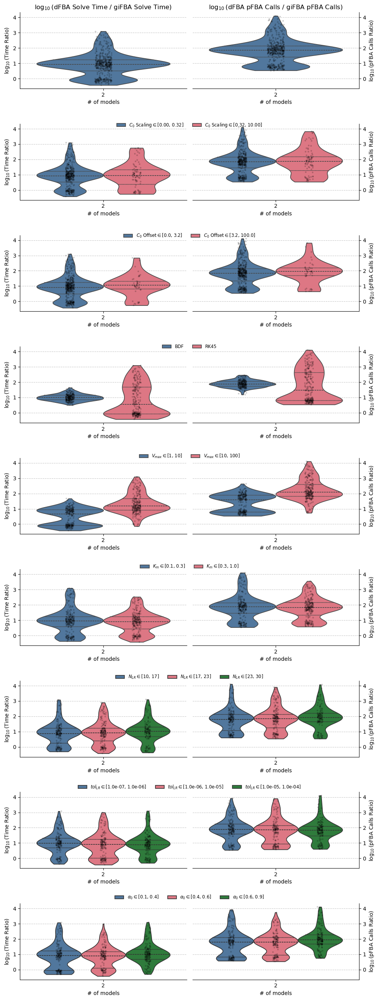

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from matplotlib.transforms import Bbox

# Color palette set via rcParams
mpl.rcParams['axes.prop_cycle'] = mpl.cycler(color=tol.bright)

Y_SCALE = "linear"

vars_eval = [
    ["N_models"],
    ["N_models", "y0_factor_binned"],
    ["N_models", "y0_offset_binned"],
    ["N_models", "solver_method"],
    ["N_models", "vmax_binned"],
    ["N_models", "km_binned"],
    ["N_models", "early_stop_window_binned"],
    ["N_models", "early_stop_tol_binned"],
    ["N_models", "rel_abund_binned"]
]

# vars_eval = vars_eval[:2]

y_min, y_max = dfba_df[["log10_time_ratio", "log10_pfba_call_ratio"]].min().min(), dfba_df[["log10_time_ratio", "log10_pfba_call_ratio"]].max().max()
y_range = y_max - y_min
y_min -= 0.05 * y_range
y_max += 0.05 * y_range

fig, axs = plt.subplots(len(vars_eval), 2, figsize=(10, 3 * len(vars_eval)))
axs = axs.flatten()


def plot_subgrouped(dfba_results, groupby_cols, row, axs, Y_SCALE="linear"):
    y_labels = [r"$\log_{10}(\text{Time Ratio})$", r"$\log_{10}(\text{pFBA Calls Ratio})$"]

    n_models_col = groupby_cols[0]
    has_subgroup = len(groupby_cols) > 1
    subgroup_col = groupby_cols[1] if has_subgroup else None

    for i, value_col in enumerate(["log10_time_ratio", "log10_pfba_call_ratio"]):
        ax = axs[row * 2 + i]
        y_label = y_labels[i]

        sns.violinplot(
            data=dfba_results,
            x=n_models_col,
            y=value_col,
            hue=subgroup_col if has_subgroup else None,
            ax=ax,
            inner="quartile",
            cut=0,
            zorder=2,
        )

        stripplot_kwargs = {
            "data": dfba_results,
            "x": n_models_col,
            "y": value_col,
            "hue": subgroup_col if has_subgroup else None,
            "dodge": has_subgroup,
            "jitter": 0.05,
            "color": "black",
            "alpha": 0.2,
            "size": 3,
            "ax": ax,
            "zorder": 3,
        }
        
        if has_subgroup:
            n_subgroups = dfba_results[subgroup_col].nunique()
            stripplot_kwargs["palette"] = ["black"] * n_subgroups

        sns.stripplot(**stripplot_kwargs)

        # Remove internal subplot legends so they don't block the plot area
        # (The handles are saved beforehand if needed, or extracted later)
        if i == 1 and ax.get_legend() is not None:
            ax.get_legend().remove()

        # Formatting, spines, and labels
        ax.set_yscale(Y_SCALE)
        ax.grid(axis="y", linestyle="--", alpha=0.7, zorder=0)
        ax.set_ylim(y_min, y_max)
        ax.margins(y=0.05)
        ax.set_xlabel("# of models")

        ax.tick_params(labelbottom=True, labelrotation=0)
        ax.set_ylabel(y_label)

        if i == 1:
            ax.spines['left'].set_visible(False)
            ax.spines['right'].set_visible(True)
            ax.yaxis.tick_right()
            ax.yaxis.set_label_position("right")
            ax.tick_params(labelright=True)
        else:
            ax.spines['right'].set_visible(False)
            ax.spines['left'].set_visible(True)
            ax.tick_params(labelleft=True)

        ax.spines['top'].set_visible(False)

        if row == 0:
            if i == 0:
                ax.set_title(r"$\log_{10}(\text{dFBA Solve Time / giFBA Solve Time})$")
            else:
                ax.set_title(r"$\log_{10}(\text{dFBA pFBA Calls / giFBA pFBA Calls})$")


# Plot each of these groupings
for row, groupby_cols in enumerate(vars_eval):
    plot_subgrouped(dfba_df, groupby_cols, row, axs, Y_SCALE=Y_SCALE)

plt.tight_layout(rect=[0, 0, 1, 0.97], h_pad=3.5)

# Place row legends
for row in range(len(vars_eval)):
    ax_left = axs[row * 2]
    ax_right = axs[row * 2 + 1]

    # ax_left.label_outer(False)
    # ax_right.label_outer(False)

    handles, labels = ax_left.get_legend_handles_labels()
    if handles:
        # Filter out stripplot legend entries if duplicated by hue
        # Keep only the unique subgroup levels for the legend
        n_subgroups = len(set(labels))
        handles = handles[:n_subgroups]
        labels = labels[:n_subgroups]

        bbox_left = ax_left.get_position()
        bbox_right = ax_right.get_position()

        combined_bbox = Bbox.union([bbox_left, bbox_right])

        fig.legend(
            handles,
            labels,
            loc="lower center",
            bbox_to_anchor=(combined_bbox.x0 + combined_bbox.width / 2, combined_bbox.y1 * 0.99),
            bbox_transform=fig.transFigure,
            ncol=len(handles),
            frameon=False,
            fontsize="small",
        )
        # Remove the remaining in-axis legend from left subplot
        if ax_left.get_legend() is not None:
            ax_left.get_legend().remove()

plt.savefig("dfba_comparison_figs/violin_plots_AH_BI.svg", dpi=300, bbox_inches="tight")

In [7]:
# show counts per binning for each variable
for var in vars_eval:
    gifba_counts_per_N_models = gifba_df.groupby("N_models", observed=False).size()
    if len(var) > 1:
        counts = dfba_df.groupby(var, observed=False).size().unstack(level=var[1])
        if len(counts.columns) == 2:
            ordinal_label_suffixes = ["Low", "High"]
        else:
            ordinal_label_suffixes = ["Low", "Medium", "High"]
        if "$\in$" in counts.columns[0]:
            new_cols = []
            for i, col in enumerate(counts.columns):
                new_cols.append(col.split("$\in$")[0].replace("$", "").replace("{", "").replace("}", "") + " " +ordinal_label_suffixes[i])
            counts.columns = new_cols

    else:
        counts = dfba_df.groupby(var, observed=False).size()

    # gifba as column in counts
    if type(counts) == pd.Series:
        counts = counts.to_frame(name="dFBA")
    counts["gifba"] = gifba_counts_per_N_models


    print(f"Counts for {var}:")
    print(counts)
    print("\n")

Counts for ['N_models']:
          dFBA  gifba
N_models             
2          500    500


Counts for ['N_models', 'y0_factor_binned']:
          C_0 Scaling Low  C_0 Scaling High  gifba
N_models                                          
2                     413                87    500


Counts for ['N_models', 'y0_offset_binned']:
          C_0 Offset Low  C_0 Offset High  gifba
N_models                                        
2                    454               46    500


Counts for ['N_models', 'solver_method']:
solver_method  BDF  RK45  gifba
N_models                       
2              248   252    500


Counts for ['N_models', 'vmax_binned']:
          V_max Low  V_max High  gifba
N_models                              
2               248         252    500


Counts for ['N_models', 'km_binned']:
          K_m Low  K_m High  gifba
N_models                          
2             250       250    500


Counts for ['N_models', 'early_stop_window_binned']:
          N_LR L

In [8]:
# evaluate accuracy of dFBA vs giFBA fluxes

def parse_simulation_series(s: pd.Series, fill_value=0.0) -> pd.DataFrame:
    """Parses a Series where each entry is a nested dict:
    {rxn_id: {org_idx: flux}} into a flattened Sparse DataFrame.
    
    Building the DataFrame column-by-column prevents large dense 
    matrices from ever being allocated in RAM.
    """
    col_data = {}
    
    # 1. Map all values by column first
    for row_idx, sim_data in s.items():
        if isinstance(sim_data, dict):
            for rxn_id, org_dict in sim_data.items():
                if isinstance(org_dict, dict):
                    for org_idx, flux in org_dict.items():
                        col_name = f"{rxn_id}___{org_idx}"
                        if col_name not in col_data:
                            col_data[col_name] = {}
                        col_data[col_name][row_idx] = flux
                        
    # 2. Build pandas SparseArrays column by column
    sparse_cols = {}
    
    # Note: If structural zeros (0.0) are common in your FBA, 
    # changing fill_value to 0.0 will save significantly more RAM.
    sparse_dtype = pd.SparseDtype(float, fill_value=fill_value)
    
    for col_name, val_dict in col_data.items():
        col_arr = [val_dict.get(idx, fill_value) for idx in s.index]
        sparse_cols[col_name] = pd.arrays.SparseArray(col_arr, dtype=sparse_dtype)
        
    return pd.DataFrame(sparse_cols, index=s.index)

gifba_fluxes_df = parse_simulation_series(df['gifba_fluxes'])
dfba_fluxes_df = parse_simulation_series(df['dfba_fluxes'])

all_nan_cols_gifba = gifba_fluxes_df.columns[gifba_fluxes_df.isna().all()].tolist()
all_nan_cols_dfba  =  dfba_fluxes_df.columns[dfba_fluxes_df.isna().all()].tolist()
all_zero_cols_gifba = gifba_fluxes_df.columns[(gifba_fluxes_df == 0).all()].tolist()
all_zero_cols_dfba = dfba_fluxes_df.columns[(dfba_fluxes_df == 0).all()].tolist()
all_nan_or_zero_cols_gifba = gifba_fluxes_df.columns[(gifba_fluxes_df.fillna(0) == 0).all()].tolist()
all_nan_or_zero_cols_dfba = dfba_fluxes_df.columns[(dfba_fluxes_df.fillna(0) == 0).all()].tolist()

all_nan_or_zero_cols_both = set(all_nan_or_zero_cols_gifba).intersection(set(all_nan_or_zero_cols_dfba))

print(f"Columns with all NaN in giFBA: {len(all_nan_cols_gifba)}")
print(f"Columns with all NaN in  dFBA: {len(all_nan_cols_dfba)}")
print()
print(f"Columns with all Zeros in giFBA: {len(all_zero_cols_gifba)}")
print(f"Columns with all Zeros in  dFBA: {len(all_zero_cols_dfba)}")
print()
print(f"Columns with all NaN/zero in giFBA: {len(all_nan_or_zero_cols_gifba)}")
print(f" Columns with all NaN/zero in dFBA: {len(all_nan_or_zero_cols_dfba)}")
print(f" Columns with all NaN/zero in both: {len(all_nan_or_zero_cols_both)}")
print()

# select only the common columns for comparison
gifba_fluxes_df_common = gifba_fluxes_df.drop(columns=all_nan_or_zero_cols_both, errors='ignore')
dfba_fluxes_df_common = dfba_fluxes_df.drop(columns=all_nan_or_zero_cols_both, errors='ignore')

# re-index and sort columns to ensure they match
gifba_fluxes_df_common = gifba_fluxes_df_common.reindex(sorted(gifba_fluxes_df_common.columns), axis=1)
dfba_fluxes_df_common = dfba_fluxes_df_common.reindex(sorted(dfba_fluxes_df_common.columns), axis=1)

print(f"Shape of giFBA fluxes DataFrame (common columns): {gifba_fluxes_df_common.shape}")
print(f" Shape of dFBA fluxes DataFrame (common columns): {dfba_fluxes_df_common.shape}")

Columns with all NaN in giFBA: 0
Columns with all NaN in  dFBA: 0

Columns with all Zeros in giFBA: 2222
Columns with all Zeros in  dFBA: 1967

Columns with all NaN/zero in giFBA: 2222
 Columns with all NaN/zero in dFBA: 1967
 Columns with all NaN/zero in both: 1944

Shape of giFBA fluxes DataFrame (common columns): (500, 844)
 Shape of dFBA fluxes DataFrame (common columns): (500, 844)


In [9]:
# ensure order of columns and indexes match
#show before sorting
print("Before sorting:")
print("giFBA: \n", gifba_fluxes_df_common.iloc[:5, :5])
print("DFBA: \n", dfba_fluxes_df_common.iloc[:5, :5])

gifba_fluxes_df_common = gifba_fluxes_df_common.sort_index(axis=0).sort_index(axis=1)
dfba_fluxes_df_common = dfba_fluxes_df_common.sort_index(axis=0).sort_index(axis=1)

# show after sorting
print("After sorting:")
print("giFBA: \n", gifba_fluxes_df_common.iloc[:, :5])
print("DFBA: \n", dfba_fluxes_df_common.iloc[:, :5])

Before sorting:
giFBA: 
              12PPDSDH___0  12aHSDHe___0  26DAPLLAT___0  2IMZS___0  4HTHDR___0
5856212_462           0.0           0.0      -0.011447        0.0    0.011447
5856212_39            0.0           0.0      -0.009489        0.0    0.009489
5856212_180           0.0           0.0      -0.010139        0.0    0.010139
5856212_43            0.0           0.0      -0.007684        0.0    0.007684
5856212_490           0.0           0.0      -0.007865        0.0    0.007865
DFBA: 
              12PPDSDH___0  12aHSDHe___0  26DAPLLAT___0  2IMZS___0  4HTHDR___0
5856212_462           0.0           0.0      -0.011447        0.0    0.011447
5856212_39            0.0           0.0      -0.009489        0.0    0.009489
5856212_180           0.0           0.0      -0.006159        0.0    0.006159
5856212_43            0.0           0.0      -0.007725        0.0    0.007725
5856212_490           0.0           0.0      -0.005137        0.0    0.005137
After sorting:
giFBA: 
        

/tmp/ipykernel_29787/2421020229.py:89: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])
/tmp/ipykernel_29787/2421020229.py:100: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])


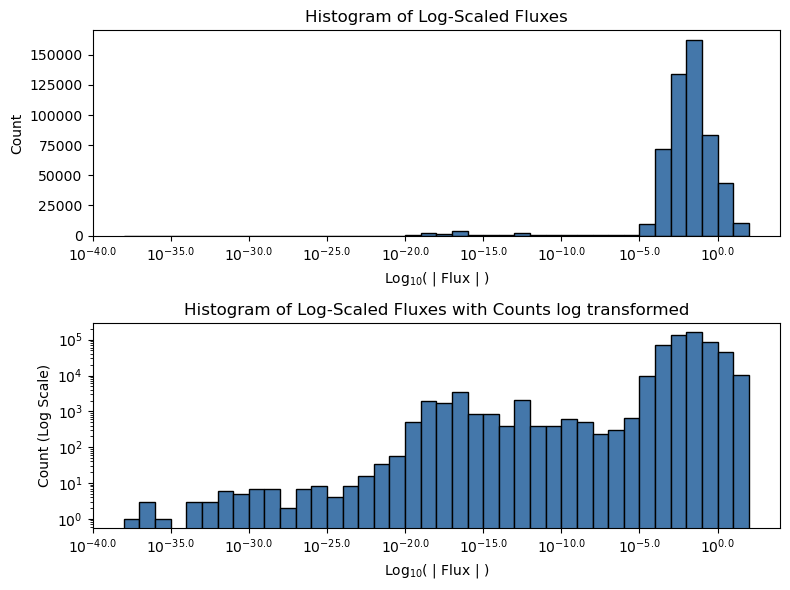

1.446705979689 496.55307039301204


/tmp/ipykernel_29787/2421020229.py:116: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0, 0].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])
/tmp/ipykernel_29787/2421020229.py:132: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1, 0].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])


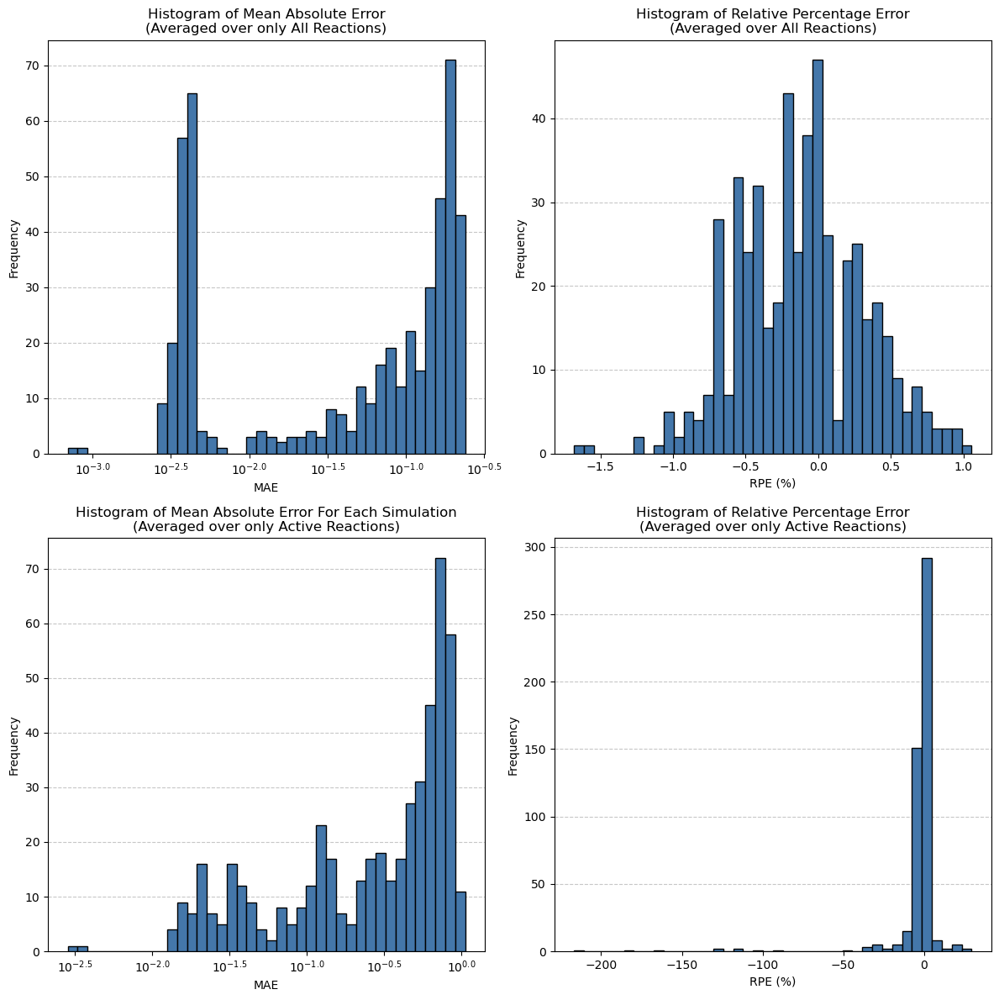

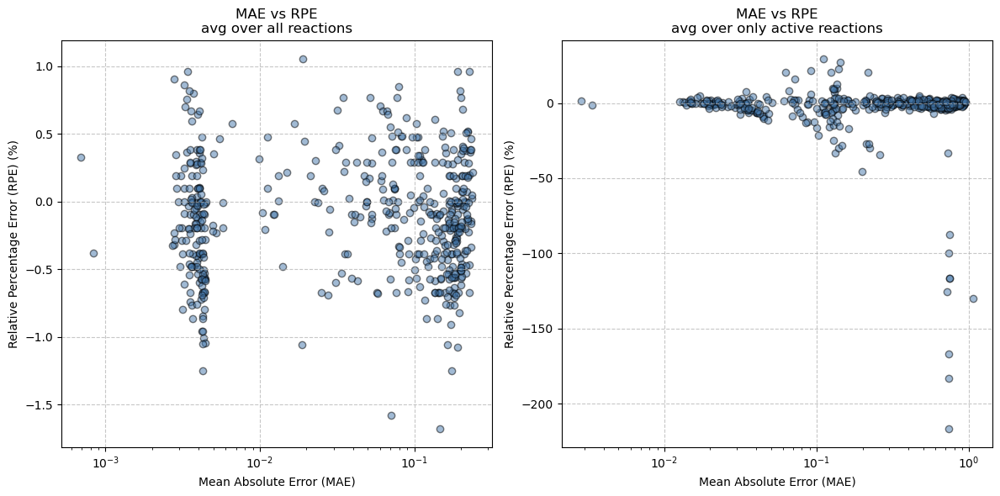

In [10]:
# quantify equivalence of fluxes between giFBA and dFBA

def calc_equivalence_metrics(gifba_fluxes_df, dfba_fluxes_df, n_rxns_series, mask_threshold=1e-6):
    """Calculate equivalence metrics between giFBA and dFBA fluxes."""
    n_rxns_series = n_rxns_series.reindex(gifba_fluxes_df.index)

    equivalence_df = pd.DataFrame(index=gifba_fluxes_df.index, columns=["Abs_Diff_Sum", "Sum_Rel_Error", "N_nonzero_rxns", "N_rxns"])

    counts_dict={}
    for (row, gifba_fluxes), (row, dfba_fluxes), n_rxns in zip(gifba_fluxes_df.iterrows(), dfba_fluxes_df.iterrows(), n_rxns_series):

        gifba_vals = gifba_fluxes[gifba_fluxes != 0].values
        dfba_vals = dfba_fluxes[dfba_fluxes != 0].values
        combined_fluxes = np.concatenate([gifba_vals, dfba_vals])

        log_vals = np.log10(np.abs(combined_fluxes))
        bin_keys = np.floor(log_vals).astype(int)

        bin_keys = np.floor(log_vals).astype(int)

        # Aggregate counts into overall dictionary
        unique_keys, counts = np.unique(bin_keys, return_counts=True)
        for key, count in zip(unique_keys, counts):
            counts_dict[key] = counts_dict.get(key, 0) + count


        # Calculate absolute differences
        abs_diff = (gifba_fluxes - dfba_fluxes).abs()
        abs_diff = abs_diff.round(12)  # Round to avoid floating-point precision issues

        diff = gifba_fluxes - dfba_fluxes

        non_zero_mask = (abs_diff >= mask_threshold)
        gifba_zeros_mask = (gifba_fluxes == 0)
        dfba_zeros_mask = (dfba_fluxes == 0)

        if non_zero_mask.sum() > 0:
            abs_diff = abs_diff
            abs_diff_sum = abs_diff.sum()

            # inf_mask = non_zero_mask | gifba_zeros_mask
            inf_mask = non_zero_mask | (dfba_zeros_mask & gifba_zeros_mask)

            rel_error = pd.Series(np.zeros(len(gifba_fluxes)), index=gifba_fluxes.index, dtype=float)
            # rpe =  2 * y_true - y_pred / |y_true| + |y_pred|  # This is a placeholder for the actual relative error calculation
            rpe = 2 * diff[~inf_mask] / (gifba_fluxes.abs()[~inf_mask] + dfba_fluxes.abs()[~inf_mask])
            rel_error = rpe
            # rel_error[~inf_mask] = (abs_diff[~gifba_zeros_mask] / gifba_fluxes[~gifba_zeros_mask]).abs()
            # rel_error[inf_mask] = abs_diff[inf_mask] / 1e-6 # sub gifba=0 to small epsilon
            # rel_error[inf_mask] = (abs_diff[inf_mask])**0.5   # use sqrt so tiny differences don't blow up relative error when gifba flux is near zero
            # rel_error[inf_mask] = abs_diff[inf_mask] # just replace with absolute difference
            rel_error = np.array(rel_error)  # Convert to numpy array for easier manipulation
            
            relative_error_sum = rel_error.sum()
            number_nonzero = non_zero_mask.sum()
        else:
            abs_diff_sum = 0.0
            relative_error_sum = 0.0
            number_nonzero = 0

        equivalence_df.loc[row, "Abs_Diff_Sum"] = abs_diff_sum
        equivalence_df.loc[row, "Sum_Rel_Error"] = relative_error_sum
        equivalence_df.loc[row, "N_nonzero_rxns"] = number_nonzero
        equivalence_df.loc[row, "N_rxns"] = n_rxns
        equivalence_df.loc[row, "Sum_Abs_Flux"] = (gifba_fluxes.abs() + dfba_fluxes.abs()).sum()
        equivalence_df.loc[row, "gifba_abs_flux_sum"] = gifba_fluxes.abs().sum()
        equivalence_df.loc[row, "dfba_abs_flux_sum"] = dfba_fluxes.abs().sum()

    # Construct complete, contiguous range of bin edges
    min_bin = min(counts_dict.keys())
    max_bin = max(counts_dict.keys())

    all_bin_edges = np.arange(min_bin, max_bin + 2, 1)
    global_counts = np.array(
        [counts_dict.get(b, 0) for b in range(min_bin, max_bin + 1)]
    )
    return equivalence_df, global_counts, all_bin_edges

eq_df, counts, bins = calc_equivalence_metrics(gifba_fluxes_df_common, dfba_fluxes_df_common, df["sum_N_rxns"])

fig, axs = plt.subplots(2, 1, figsize=(8, 6))
axs[0].bar(
    bins[:-1], counts, width=1, align="edge", edgecolor="black"
)
axs[0].set_xlabel(r"Log$_{10}$( | Flux | )")
axs[0].set_ylabel("Count")
axs[0].set_title("Histogram of Log-Scaled Fluxes")
x_ticks = axs[0].get_xticks()
axs[0].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])

axs[1].bar(
    bins[:-1], counts, width=1, align="edge", edgecolor="black"
)
axs[1].set_xlabel(r"Log$_{10}$( | Flux | )")
axs[1].set_ylabel("Count (Log Scale)")
axs[1].set_title("Histogram of Log-Scaled Fluxes with Counts log transformed")
axs[1].set_yscale("log")
x_ticks = axs[1].get_xticks()
# get x_ticks and then replace with 10^{x ticks existing}
axs[1].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(2, 2, figsize=(12, 12))

n_bins = 40
# for col in eq_df.columns:
#     print(col, eq_df[col].unique())
print(min(eq_df["Abs_Diff_Sum"]), max(eq_df["Abs_Diff_Sum"]))
mae_all = (eq_df["Abs_Diff_Sum"]/eq_df["N_rxns"]).astype(float)
axs[0, 0].hist(np.log10(mae_all), bins=n_bins, edgecolor="black", zorder=3)
axs[0, 0].set_title("Histogram of Mean Absolute Error\n(Averaged over only All Reactions)")
axs[0, 0].set_xlabel("MAE")
axs[0, 0].set_ylabel("Frequency")
x_ticks = axs[0, 0].get_xticks()
axs[0, 0].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])

rpe_all = (eq_df["Sum_Rel_Error"]/eq_df["N_rxns"]).astype(float)
axs[0, 1].hist(rpe_all * 100, bins=n_bins, edgecolor="black", zorder=3)
axs[0, 1].set_title("Histogram of Relative Percentage Error\n(Averaged over All Reactions)")
axs[0, 1].set_xlabel("RPE (%)")
axs[0, 1].set_ylabel("Frequency")


denom_nonzero = (eq_df["N_nonzero_rxns"] == 0).astype(int)
mae_nonzero = (eq_df["Abs_Diff_Sum"]/(eq_df["N_nonzero_rxns"]+denom_nonzero)).astype(float) # add 0 if nonzero, add 1 if zero to avoid division by zero
axs[1, 0].hist(np.log10(mae_nonzero), bins=n_bins, edgecolor="black", zorder=3)
axs[1, 0].set_title("Histogram of Mean Absolute Error For Each Simulation\n(Averaged over only Active Reactions)")
axs[1, 0].set_xlabel("MAE")
axs[1, 0].set_ylabel("Frequency")
x_ticks = axs[1, 0].get_xticks()
axs[1, 0].set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])


rpe_nonzero = (eq_df["Sum_Rel_Error"]/(eq_df["N_nonzero_rxns"]+denom_nonzero)).astype(float)
axs[1, 1].hist(rpe_nonzero * 100, bins=n_bins, edgecolor="black", zorder=3)
axs[1, 1].set_title("Histogram of Relative Percentage Error\n(Averaged over only Active Reactions)")
axs[1, 1].set_xlabel("RPE (%)")
axs[1, 1].set_ylabel("Frequency")


axs[0, 0].grid(axis="y", linestyle="--", alpha=0.7, zorder=0)
axs[0, 1].grid(axis="y", linestyle="--", alpha=0.7, zorder=0)
axs[1, 0].grid(axis="y", linestyle="--", alpha=0.7, zorder=0)
axs[1, 1].grid(axis="y", linestyle="--", alpha=0.7, zorder=0)

plt.tight_layout()

eq_df["MAE_all"] = mae_all
eq_df["RPE_all"] = rpe_all
eq_df["MAE_nonzero"] = mae_nonzero
eq_df["RPE_nonzero"] = rpe_nonzero


# plot mae vs rpe for each simulation
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].scatter(eq_df["MAE_all"], eq_df["RPE_all"] * 100, alpha=0.5, edgecolor='k')
axs[0].set_xscale("log")
axs[0].set_xlabel("Mean Absolute Error (MAE)")
axs[0].set_ylabel("Relative Percentage Error (RPE) (%)")
axs[0].set_title("MAE vs RPE\navg over all reactions")
axs[0].grid(axis="both", linestyle="--", alpha=0.7)

axs[1].scatter(eq_df["MAE_nonzero"], eq_df["RPE_nonzero"] * 100, alpha=0.5, edgecolor='k')
axs[1].set_xscale("log")
axs[1].set_xlabel("Mean Absolute Error (MAE)")
axs[1].set_ylabel("Relative Percentage Error (RPE) (%)")
axs[1].set_title("MAE vs RPE\navg over only active reactions")
axs[1].grid(axis="both", linestyle="--", alpha=0.7)

plt.tight_layout()



In [11]:
for quant in range(0, 101, 1):
    mae_all_quantile = np.percentile(np.log10(eq_df["MAE_all"].values), quant)
    print(f"{quant}th percentile: MAE_all={mae_all_quantile:.6f}")

0th percentile: MAE_all=-3.158309
1th percentile: MAE_all=-2.554352
2th percentile: MAE_all=-2.530677
3th percentile: MAE_all=-2.504158
4th percentile: MAE_all=-2.490197
5th percentile: MAE_all=-2.481193
6th percentile: MAE_all=-2.463395
7th percentile: MAE_all=-2.455089
8th percentile: MAE_all=-2.450859
9th percentile: MAE_all=-2.445687
10th percentile: MAE_all=-2.442658
11th percentile: MAE_all=-2.436977
12th percentile: MAE_all=-2.424238
13th percentile: MAE_all=-2.414855
14th percentile: MAE_all=-2.410329
15th percentile: MAE_all=-2.407582
16th percentile: MAE_all=-2.405952
17th percentile: MAE_all=-2.403131
18th percentile: MAE_all=-2.391853
19th percentile: MAE_all=-2.390823
20th percentile: MAE_all=-2.389527
21th percentile: MAE_all=-2.382566
22th percentile: MAE_all=-2.379779
23th percentile: MAE_all=-2.375341
24th percentile: MAE_all=-2.373936
25th percentile: MAE_all=-2.371387
26th percentile: MAE_all=-2.368130
27th percentile: MAE_all=-2.366278
28th percentile: MAE_all=-2.36

In [12]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go
from tol_colors import colors

# 3d plot
# x= gifba efficiency, y= dfba efficiency, z= error metric


df = df.reindex(sorted(df.index), axis=0)
times = df["dfba_termination_t"]
masks = times == 100
print(sum(masks), "out of", len(masks), "simulations terminated without convergence")

# samples with 0 error because 0 growth
zero_error_mask = (eq_df["MAE_all"] == 0) & (eq_df["RPE_all"] == 0)
print(sum(zero_error_mask), "out of", len(zero_error_mask), "simulations have 0 error due to 0 growth")
zero_growth_mask = eq_df["Sum_Abs_Flux"] == 0
print(sum(zero_growth_mask), "out of", len(zero_growth_mask), "simulations have 0 growth")

eq_df = eq_df.reindex(sorted(eq_df.index), axis=0)
gifba_df = gifba_df.reindex(sorted(eq_df.index), axis=0)
dfba_df = dfba_df.reindex(sorted(eq_df.index), axis=0)


eq_df_filtered = eq_df[~zero_growth_mask]
gifba_df_filtered = gifba_df[~zero_growth_mask]
dfba_df_filtered = dfba_df[~zero_growth_mask]

# X_data = times.loc[dfba_df_filtered.index]
# X_lab = "Simulation Time (s)"
# X_scale = "log"
X_data = dfba_df_filtered["dfba_pfba_calls"].values
X_lab = "# Pfba Calls"
X_scale = "log"

Y_data = dfba_df_filtered["vmax"].values
Y_lab = "Vmax"
Y_scale = "log"

Z_data = eq_df_filtered["MAE_all"].values
Z_lab = "MAE"
Z_scale = "linear"

# plot quantile clustering of equivalence metric
q_eval = 0.93
quantile_threshold = eq_df_filtered["MAE_all"].abs().quantile(q_eval)
category = eq_df_filtered["MAE_all"].abs() >= quantile_threshold




fig = make_subplots(
    rows=1, cols=3,
    specs=[[{"type": "scene"}, {"type": "xy"}, {"type": "xy"}]],
    subplot_titles=("3D Scatter Plot of Simulation Time vs Vmax vs MAE", 
                    "Best MAE Example (logMAE={:.2e})".format(np.log10(eq_df_filtered["MAE_all"].min())), 
                    "Worst MAE Example (logMAE={:.2e})".format(np.log10(eq_df_filtered["MAE_all"].max()))
                    )
)

solver_methods = (dfba_df_filtered.solver_method == "RK45").to_numpy().astype(int)
bdf_mask = solver_methods == 0
rk45_mask = solver_methods == 1

fig.add_trace(go.Scatter3d(
    x=X_data[bdf_mask], y=Y_data[bdf_mask], z=Z_data[bdf_mask],
    mode="markers", name="BDF",
    marker=dict(size=4, color="steelblue", opacity=0.8),
    legend="legend"
), row=1, col=1)

fig.add_trace(go.Scatter3d(
    x=X_data[rk45_mask], y=Y_data[rk45_mask], z=Z_data[rk45_mask],
    mode="markers", name="RK45",
    marker=dict(size=4, color="crimson", opacity=0.8),
    legend="legend"
), row=1, col=1)

# find best and worst MAE to show in 2nd & 3rd plots
best_idx = eq_df_filtered["MAE_all"].idxmin()
worst_idx = eq_df_filtered["MAE_all"].idxmax()
def add_flux_traces(gifba_s, dfba_s, legend, col):
    """Add AH/BI scatter traces whose hover label shows the reaction name (index)."""
    is_ah = gifba_s.index.str.endswith("___0")

    for mask, name, color in [(is_ah, "AH (___0)", "crimson"),
                              (~is_ah, "BI (___1)", "steelblue")]:
        fig.add_trace(go.Scatter(
            x=gifba_s[mask], y=dfba_s[mask],
            mode="markers", name=name,
            text=gifba_s.index[mask],  # reaction names
            hovertemplate=(
                "<b>%{text}</b><br>"
                "GIFBA: %{x:.4g}<br>"
                "dFBA: %{y:.4g}"
                f"<extra>{name}</extra>"
            ),
            marker=dict(color=color, opacity=0.6),
            legend=legend,
        ), row=1, col=col)

    # get min/max for y=x line
    min_y_x = min(gifba_s.min(), dfba_s.min())
    max_y_x = max(gifba_s.max(), dfba_s.max())
    fig.add_trace(go.Scatter(
        x=[min_y_x, max_y_x], y=[min_y_x, max_y_x],
        mode="lines", name="y=x",
        line=dict(color='rgba(0, 0, 0, 0.5)', dash="dash"),
        legend=legend,
    ), row=1, col=col)

# make sure both Series are in the same reaction order before masking
gifba_best = gifba_fluxes_df_common.loc[best_idx]
dfba_best = dfba_fluxes_df_common.loc[best_idx].reindex(gifba_best.index)
add_flux_traces(gifba_best, dfba_best, "legend2", 2)

gifba_worst = gifba_fluxes_df_common.loc[worst_idx]
dfba_worst = dfba_fluxes_df_common.loc[worst_idx].reindex(gifba_worst.index)
add_flux_traces(gifba_worst, dfba_worst, "legend3", 3)

# Extract parameter values for best and worst MAE examples
param_cols = ["vmax", "km", "rel_abund", "y0_factor", "y0_offset", "early_stop_window", "early_stop_tol", "gifba_iter_converged", "gifba_periodicity", "dfba_pfba_calls", "gifba_pfba_calls"]
best_params = df.loc[best_idx, param_cols]
worst_params = df.loc[worst_idx, param_cols]

# Format parameters as clean text strings
best_param_str = "<br>".join([f"<b>{k}</b>: {v:.4g}" if isinstance(v, (int, float)) else f"<b>{k}</b>: {v}" for k, v in best_params.items()])
worst_param_str = "<br>".join([f"<b>{k}</b>: {v:.4g}" if isinstance(v, (int, float)) else f"<b>{k}</b>: {v}" for k, v in worst_params.items()])

fig.update_layout(
    scene=dict(
        xaxis_title=X_lab,
        yaxis_title=Y_lab,
        zaxis_title=Z_lab,
        xaxis=dict(type=X_scale, showgrid=True, zeroline=True, showticklabels=True),
        yaxis=dict(type=Y_scale, showgrid=True, zeroline=True, showticklabels=True),
        zaxis=dict(type=Z_scale, showgrid=True, zeroline=True, showticklabels=True),
    ),
    height=820,  
    showlegend=True,
    margin=dict(b=260),  # Increased bottom margin to fit legends and parameter lists
    
    # Position each legend horizontally centered below its corresponding column
    legend=dict(
        title=dict(text="Solver Method"),
        orientation="h",
        x=0.15, y=-0.12,
        xanchor="center", yanchor="top"
    ),
    legend2=dict(
        title=dict(text=f"Best Run (MAE=  {eq_df_filtered.loc[best_idx, 'MAE_all']:.2e})"),
        orientation="h",
        x=0.50, y=-0.12,
        xanchor="center", yanchor="top"
    ),
    legend3=dict(
        title=dict(text=f"Worst Run (MAE=  {eq_df_filtered.loc[worst_idx, 'MAE_all']:.2e})"),
        orientation="h",
        x=0.85, y=-0.12,
        xanchor="center", yanchor="top"
    ),
    
    # Add parameter value annotations underneath the legends of the 2nd and 3rd subplots
    annotations=[
        dict(
            text=f"<b>Best Parameters:</b><br>{best_param_str}",
            x=0.50, y=-0.2,
            xref="paper", yref="paper",
            showarrow=False,
            xanchor="center", yanchor="top",
            align="left",
            font=dict(size=10)
        ),
        dict(
            text=f"<b>Worst Parameters:</b><br>{worst_param_str}",
            x=0.85, y=-0.2,
            xref="paper", yref="paper",
            showarrow=False,
            xanchor="center", yanchor="top",
            align="left",
            font=dict(size=10)
        )
    ]
)

fig.show()

# save fig as html
os.makedirs("dfba_comparison_figs", exist_ok=True)
fig.write_html("dfba_comparison_figs/3d_scatter_efficiency_vmax_mae.html")

475 out of 500 simulations terminated without convergence
0 out of 500 simulations have 0 error due to 0 growth
0 out of 500 simulations have 0 growth


In [125]:

# N = np.random.randint(1, 10)
N=10
print(N)
ra = np.random.dirichlet(np.ones(N)*0.5, size=1).flatten()
while min(ra) < 0.05 or ra.round(6).sum() != 1.0:
    ra = np.random.dirichlet(np.ones(N)*0.5, size=1).flatten()

ra
print("Min", min(ra))
print("Max", max(ra))
print("Sum", sum(ra))
list([ra.round(6).sum()])


10
Min 0.05279613416728883
Max 0.14564816765835306
Sum 1.0


[1.0]

Top 1.0% worst MAE threshold: 0.232337
Top 1.0% best MAE threshold: 0.002790


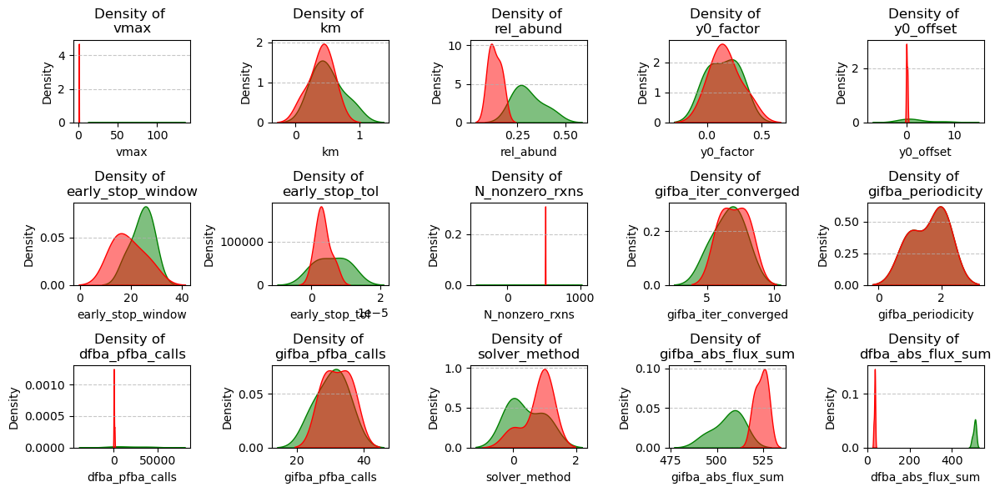

In [16]:
# show top 5% best and worst MAE and their parameter values
percentile = 0.01
mae_worst_percentile = eq_df_filtered["MAE_all"].quantile(1 - percentile)
mae_best_percentile = eq_df_filtered["MAE_all"].quantile(percentile)

print(f"Top {percentile*100}% worst MAE threshold: {mae_worst_percentile:.6f}")
worst_mae_indices = eq_df_filtered[eq_df_filtered["MAE_all"] >= mae_worst_percentile].index

print(f"Top {percentile*100}% best MAE threshold: {mae_best_percentile:.6f}")
best_mae_indices = eq_df_filtered[eq_df_filtered["MAE_all"] <= mae_best_percentile].index

# plot distributions of parameter values for best and worst MAE simulations
param_cols = ["vmax", "km", "rel_abund", "y0_factor", 
              "y0_offset", "early_stop_window", "early_stop_tol", 
              "N_nonzero_rxns", "gifba_iter_converged", 
              "gifba_periodicity", "dfba_pfba_calls", "gifba_pfba_calls",
              "solver_method", "gifba_abs_flux_sum", "dfba_abs_flux_sum"]
best_mae_df = df.loc[best_mae_indices]
worst_mae_df = df.loc[worst_mae_indices]

# add columns from eq_df_filtered to best_mae_df and worst_mae_df
best_mae_df = best_mae_df.join(eq_df_filtered)
worst_mae_df = worst_mae_df.join(eq_df_filtered)

fig, axs = plt.subplots(3, len(param_cols)//3 + len(param_cols)%3, figsize=(12, 6))
axs = axs.flatten()

for i, param in enumerate(param_cols):
    if param in eq_df_filtered.columns:
        param_vals = eq_df_filtered[param]
    elif param in df.columns:
        param_vals = df[param]

    if param == "solver_method":
        param_vals = param_vals.map({"RK45": 1, "BDF": 0})
    sns.kdeplot(param_vals.loc[best_mae_indices], ax=axs[i], label="Best MAE", color="green", warn_singular=False, fill=True, alpha=0.5)
    sns.kdeplot(param_vals.loc[worst_mae_indices], ax=axs[i], label="Worst MAE", color="red", warn_singular=False, fill=True, alpha=0.5)
    axs[i].set_xlabel(param)
    axs[i].grid(axis="y", linestyle="--", alpha=0.7, zorder=0)
    axs[i].margins(y=0.05)
    axs[i].set_title("Density of \n{}".format(param))
plt.tight_layout()





In [ ]:
best_mae_df

,N_models,rel_abund,y0_factor,y0_offset,media,sum_N_rxns,sum_N_mets,vmax,km,solver_method,...,Sum_Rel_Error,N_nonzero_rxns,N_rxns,Sum_Abs_Flux,gifba_abs_flux_sum,dfba_abs_flux_sum,MAE_all,RPE_all,MAE_nonzero,RPE_nonzero
5856212_11,2,0.423232,0.003275,7.054802,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,28.480359,0.443062,NaN,...,1.999688,93,2083,987.508103,493.753071,493.755033,0.003241,9.600041e-04,0.072586,2.150203e-02
5856212_168,2,0.415152,0.065793,0.037649,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,65.793322,0.196304,NaN,...,-16.666548,50,2083,989.171434,494.585788,494.585646,0.003168,-8.001223e-03,0.131964,-3.333310e-01
5856212_17,2,0.277778,0.151991,0.075646,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,54.622772,0.151991,NaN,...,-6.588315,72,2083,1017.482643,508.741978,508.740665,0.002790,-3.162897e-03,0.080725,-9.150438e-02
5856212_191,2,0.253535,0.132194,0.343047,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,91.116276,0.792483,NaN,...,5.165447,508,2083,1023.516328,511.240130,512.276198,0.003226,2.479811e-03,0.013229,1.016820e-02
5856212_201,2,0.423232,0.004329,1.384886,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,62.802914,0.533670,NaN,...,-7.899968,515,2083,989.092490,493.753071,495.339419,0.000834,-3.792591e-03,0.003371,-1.533974e-02
5856212_222,2,0.245455,0.305386,0.343047,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,75.646333,0.509414,NaN,...,-6.818153,81,2083,1024.144514,512.072847,512.071667,0.002699,-3.273237e-03,0.069395,-8.417472e-02
5856212_240,2,0.205051,0.013219,0.067342,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,100.000000,0.533670,NaN,...,3.971197,509,2083,1033.364271,516.236432,517.127839,0.003085,1.906480e-03,0.012624,7.801959e-03
5856212_245,2,0.277778,0.046416,0.385353,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,83.021757,0.521401,NaN,...,7.180489,91,2083,1017.496927,508.741978,508.754948,0.002866,3.447186e-03,0.065593,7.890648e-02
5856212_267,2,0.277778,0.018738,0.010476,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,68.926121,0.849753,NaN,...,4.000071,65,2083,1017.486008,508.741978,508.744030,0.002852,1.920341e-03,0.091407,6.153955e-02
5856212_28,2,0.382828,0.100000,0.151991,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,41.320124,0.114976,NaN,...,-4.00001,63,2083,995.834292,497.916656,497.917636,0.003132,-1.920312e-03,0.103567,-6.349222e-02


In [ ]:
worst_mae_df

,N_models,rel_abund,y0_factor,y0_offset,media,sum_N_rxns,sum_N_mets,vmax,km,solver_method,...,Sum_Rel_Error,N_nonzero_rxns,N_rxns,Sum_Abs_Flux,gifba_abs_flux_sum,dfba_abs_flux_sum,MAE_all,RPE_all,MAE_nonzero,RPE_nonzero
5856212_1,2,0.148485,0.174753,0.135305,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,1.917910,0.497702,NaN,...,10.741,522,2083,581.799797,522.065452,59.734345,0.222232,0.005157,0.886798,0.020577
5856212_105,2,0.196970,0.200923,0.120450,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,1.917910,0.178865,NaN,...,-2.78392,523,2083,579.711788,517.069149,62.642639,0.218536,-0.001336,0.870382,-0.005323
5856212_128,2,0.108081,0.162975,0.001451,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,2.104904,0.830218,NaN,...,-4.658281,521,2083,589.128666,526.229037,62.899629,0.222846,-0.002236,0.890956,-0.008941
5856212_139,2,0.261616,0.086975,0.016681,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,1.149757,0.977010,NaN,...,20.0,521,2083,550.192824,510.407413,39.785411,0.226241,0.009602,0.904528,0.038388
5856212_143,2,0.132323,0.008111,0.271859,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,1.321941,0.109750,NaN,...,-2.95082,525,2083,564.264759,523.730886,40.533873,0.232141,-0.001417,0.921047,-0.005621
5856212_177,2,0.116162,0.613591,0.000911,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,1.384886,0.104762,NaN,...,9.612366,523,2083,567.168101,525.396320,41.771780,0.232332,0.004615,0.925331,0.018379
5856212_194,2,0.124242,0.123285,0.001150,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,1.204504,0.359381,NaN,...,0.456552,522,2083,561.182160,524.563603,36.618557,0.234394,0.000219,0.935332,0.000875
5856212_208,2,0.132323,0.001630,1.384886,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,1.321941,0.210490,NaN,...,-3.463849,521,2083,564.258783,523.730886,40.527897,0.232104,-0.001663,0.927970,-0.006648
5856212_214,2,0.180808,0.081113,0.486260,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,1.384886,0.359381,NaN,...,-9.729908,522,2083,563.259436,518.734583,44.524853,0.227900,-0.004671,0.909418,-0.018640
5856212_242,2,0.285859,0.002477,1.097499,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,1.321941,0.890215,NaN,...,3.972028,522,2083,554.651247,507.909261,46.741986,0.221557,0.001907,0.884105,0.007609


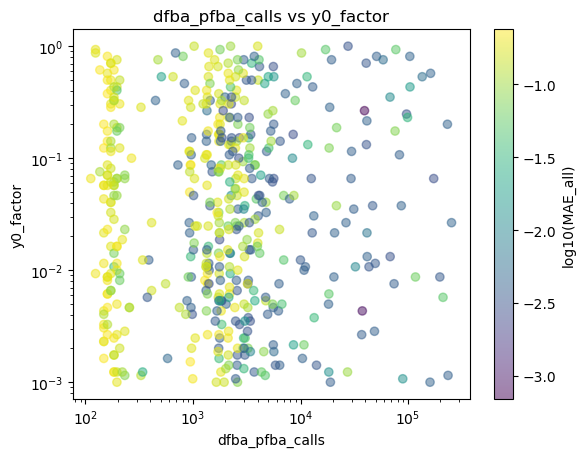

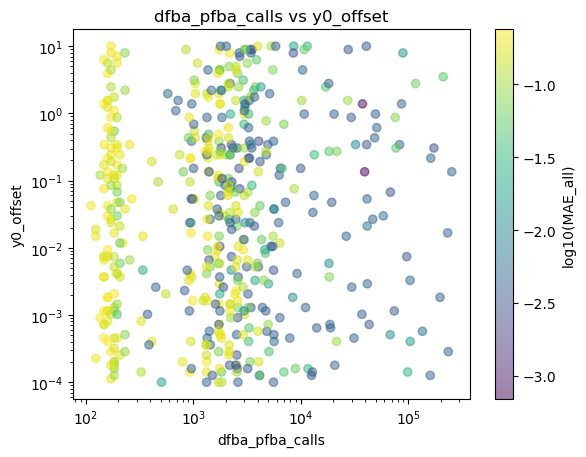

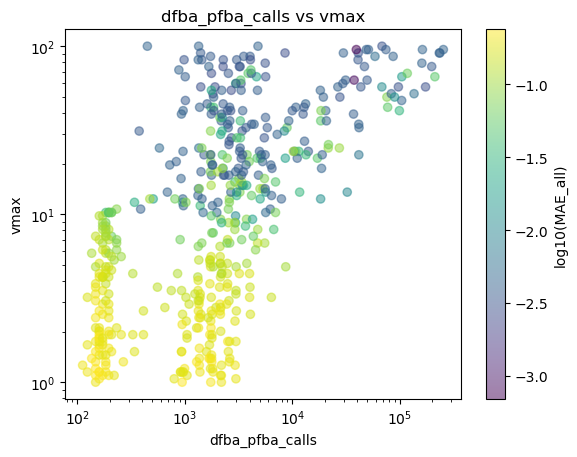

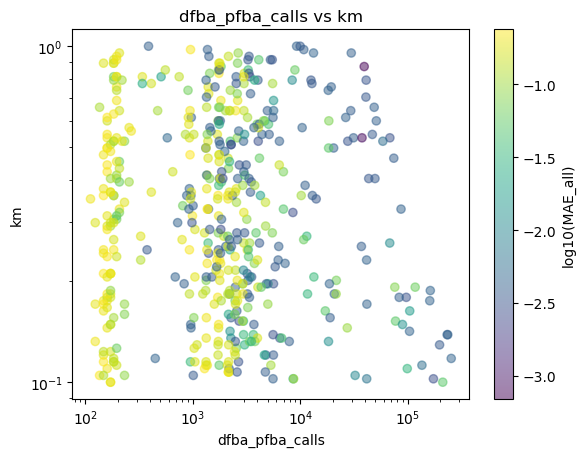

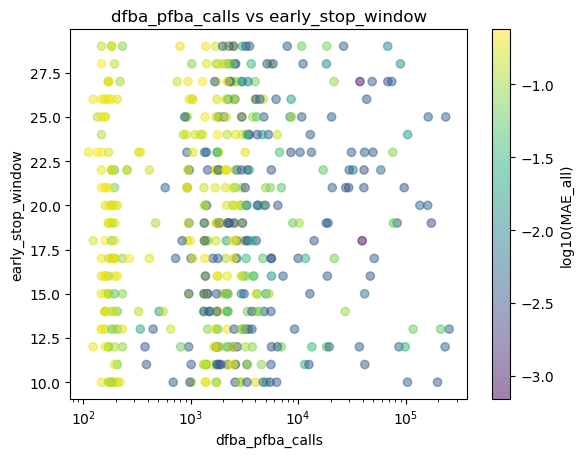

...

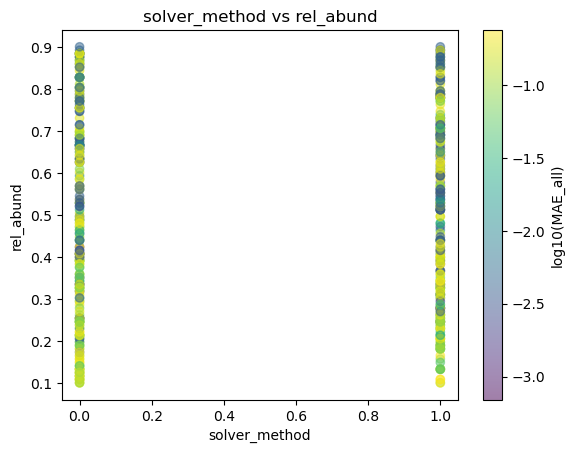

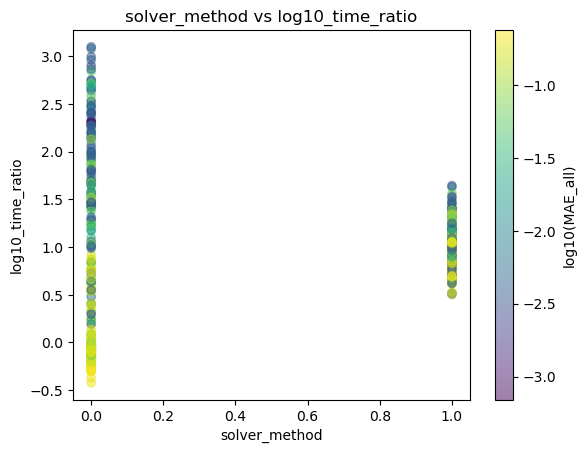

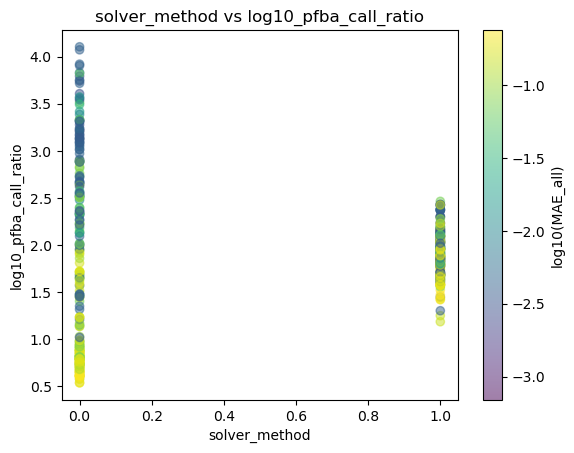

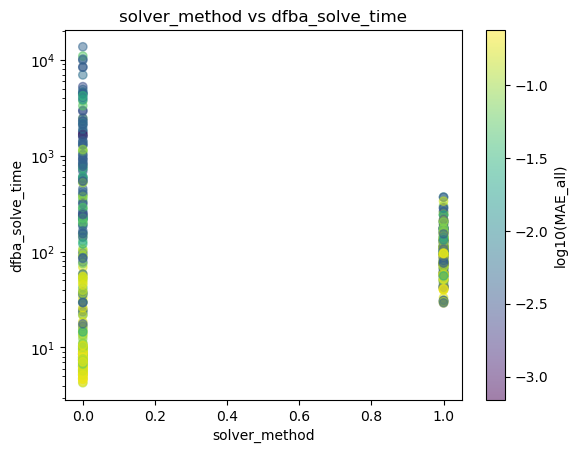

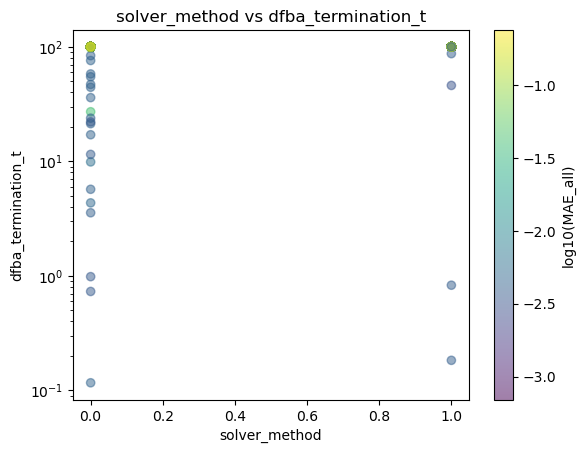

In [ ]:
cols_scale_dict = {"dfba_pfba_calls": "linear", 
        "y0_factor": "log", 
        "y0_offset": "log", 
        "vmax": "log", 
        "km": "log", 
        "early_stop_window": "linear", 
        "early_stop_tol": "log", 
        "rel_abund": "linear", 
        "log10_time_ratio": "linear", 
        "log10_pfba_call_ratio": "linear", 
        "dfba_solve_time": "log", 
        "dfba_pfba_calls": "log", 
        "dfba_termination_t": "log", 
        "solver_method": "linear"
}

# print(df_tmp)
# print(eq_df)
df_tmp = df.loc[eq_df.index].copy()
df_tmp["solver_method"] = df["solver_method"].map({"RK45": 0, "BDF": 1})

q_eval = 0.93
quantile_threshold = eq_df["MAE_all"].abs().quantile(q_eval)
category = eq_df["MAE_all"].abs() >= quantile_threshold
c = category.map({True: "crimson", False: "steelblue"})
# c= eq_df["RPE_all"].abs()
c = np.log10(eq_df["MAE_all"].abs())



# select only the rows that match eq_df index
for col in cols_scale_dict.keys():
    for col2 in cols_scale_dict.keys():
        if col != col2:
            plt.scatter(df_tmp[col], df_tmp[col2], c=c, cmap="viridis", alpha=0.5)
            plt.xscale(cols_scale_dict[col])
            plt.yscale(cols_scale_dict[col2])
            cbar = plt.colorbar()
            cbar.set_label("log10(MAE_all)")
            plt.title(f"{col} vs {col2}")
            plt.xlabel(col)
            plt.ylabel(col2)
            plt.show()
    # for color_col in cols:
            # plt.scatter(df_tmp[col], eq_df["MAE_all"], color=colors, alpha=0.5)
            # plt.title(f"{col} vs MAE_all")
            plt.show()